# El tamaño final: resolver la relación y compararla con el curso simulado

- **Nivel:** 2, El método en la práctica
- **Prerrequisitos:** cuaderno 01 de este tema
- **Tiempo de lectura:** unos 25 minutos

## Objetivos

Al terminar este cuaderno puedes:

- resolver $z = 1 - e^{-R_0 z}$ numéricamente y dibujar su solución contra $R_0$;
- ubicar los casos calculados sobre esa curva;
- mostrar que dos corridas con el mismo $R_0$ y distinto curso temporal terminan en el mismo tamaño final.

## Preparación

El entorno de los cuadernos está fijado en `notebooks/requirements.txt` y se construye con `scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows). Los paquetes que usa este cuaderno, con sus versiones exactas:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

Este producto de ejemplo no publica un paquete propio: su método vive en `data-pipeline/pipeline/`, así que el cuaderno importa ese código por su ruta. Un producto importa en cambio su propio paquete de PyPI (`pip install <paquete>==<versión>`).

La siguiente celda importa las herramientas e imprime sus versiones.

In [1]:
# Imprimir las versiones de las herramientas de este cuaderno, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json

import numpy as np
import matplotlib.pyplot as plt

for name in ("numpy", "matplotlib"):
    print(name, md.version(name))

numpy 2.4.6
matplotlib 3.11.2


El motor se importa desde `data-pipeline/` por su ruta, como en el tema 01.

In [2]:
# El cuaderno está tres carpetas bajo la raíz del repositorio; los módulos del pipeline se importan por su ruta
import sys
from pathlib import Path

ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.model.sir import simulate
from pipeline.io.schema import SIRParams
from pipeline.oracles import final_size

print(simulate.__module__, SIRParams.__module__)

pipeline.model.sir pipeline.io.schema


## Datos

Los parámetros de los cinco casos calculados.

- Propietario: este repositorio (el ejemplo de la plantilla de producto), https://github.com/fsantibanezleal/CAOS_PRODUCT_TEMPLATE.
- Clase de licencia: datos sintéticos que el pipeline produce desde los parámetros de cada manifiesto (`real_or_synthetic` es `synthetic`); no hay conjunto de datos de terceros, así que no aplica licencia de datos, y la licencia MIT del repositorio cubre los artefactos.
- Archivos leídos: `data/derived/manifests/index.json`, `data/derived/manifests/<case>.json`.

La siguiente celda define los lectores y lista los casos.

In [3]:
# Dos lectores de los artefactos versionados: un archivo ausente detiene el cuaderno y nombra su ruta
def read_json(relative):
    return json.loads((ROOT / "data" / "derived" / relative).read_text(encoding="utf-8"))


def params_of(case_id):
    p = read_json(f"manifests/{case_id}.json")["params"]
    return SIRParams(case_id, p["beta"], p["gamma"], p["N"], p["I0"], p["days"])


CASES = [c["case_id"] for c in read_json("manifests/index.json")["cases"]]
OUTBREAKS = [c for c in CASES if c.startswith("EX")]
SUPERCRITICAL = [c for c in OUTBREAKS if params_of(c).beta > params_of(c).gamma]
print(CASES)
print("casos que pueden despegar:", SUPERCRITICAL)

['CTRL_degenerate', 'EX01_subcritical', 'EX02_epidemic', 'EX03_fast_burn', 'EX04_slow_spread']
casos que pueden despegar: ['EX02_epidemic', 'EX03_fast_burn', 'EX04_slow_spread']


## Método

La fracción $z$ de la población que llega a infectarse resuelve la relación del tamaño final (Kermack y McKendrick, 1927; Miller, 2012):

$$z = 1 - e^{-R_0 z}$$

No contiene la tasa de contacto ni la de recuperación por separado, solo su cociente, ni ningún tiempo: es independiente del curso temporal. La celda siguiente llama a `final_size` de `data-pipeline/pipeline/oracles.py`, un oráculo que no comparte código con el motor y la resuelve por iteración de punto fijo: partiendo de $z = 1$, repite $z \leftarrow 1 - e^{-R_0 z}$ hasta que deja de cambiar. Imprime las primeras iteraciones del caso de epidemia, para ver la convergencia.

In [4]:
# Resolver la relación del tamaño final por iteración de punto fijo, imprimiendo las primeras iteraciones y su cantidad para R0 = 2,75
first = []
solution = final_size(2.75, trace=first)
print("primeras iteraciones:", [round(float(v), 5) for v in first[:6]], "... iteraciones en total:", len(first))
print("z =", round(solution, 6))

primeras iteraciones: [0.93607, 0.92379, 0.92117, 0.9206, 0.92047, 0.92044] ... iteraciones en total: 18
z = 0.920437


Ahora la solución para un rango de $R_0$, con los cuatro casos calculados ubicados sobre la curva en su $R_0$ y su tasa de ataque simulada (la parte de la población en R al final del horizonte). La celda lista también los números.

EX01_subcritical   R0= 0.72  z=0.0000  simulado=0.0018
EX02_epidemic      R0= 2.75  z=0.9204  simulado=0.9237
EX03_fast_burn     R0= 6.00  z=0.9975  simulado=0.9982
EX04_slow_spread   R0= 1.20  z=0.3137  simulado=0.2993


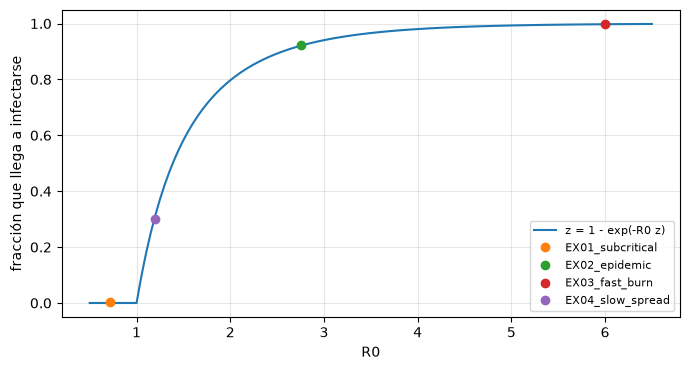

In [5]:
# Dibujar z contra R0 y ubicar cada caso calculado en (R0, tasa de ataque simulada)
grid = np.linspace(0.5, 6.5, 121)
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(grid, [final_size(g) for g in grid], label="z = 1 - exp(-R0 z)")
for case_id in OUTBREAKS:
    p = params_of(case_id)
    r = simulate(p)
    r0 = p.beta / p.gamma
    ax.plot([r0], [r.attack_rate], "o", label=case_id)
    print(f"{case_id:18s} R0={r0:5.2f}  z={final_size(r0):.4f}  simulado={r.attack_rate:.4f}")
ax.set_xlabel("R0")
ax.set_ylabel("fracción que llega a infectarse")
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

La relación dice que el curso temporal no importa. Para comprobarlo, esta celda corre dos casos con el mismo $R_0 = 2{,}75$: el caso de epidemia ($\beta = 0{,}55$, $\gamma = 0{,}20$) y uno el doble de rápido ($\beta = 1{,}10$, $\gamma = 0{,}40$). El pico debería llegar casi el doble de pronto y el tamaño final debería ser el mismo.

In [6]:
# Dos corridas con el mismo R0 y distinta velocidad: el pico se mueve, el tamaño final no
base = params_of("EX02_epidemic")
fast = SIRParams("twice_as_fast", base.beta * 2, base.gamma * 2, base.N, base.I0, base.days)
for label, q in (("EX02_epidemic", base), ("el doble de rápido", fast)):
    r = simulate(q)
    print(f"{label:18s} R0={q.beta / q.gamma:.2f}  pico el día {r.t_peak:6.2f}  tasa de ataque={r.attack_rate:.4f}")

EX02_epidemic      R0=2.75  pico el día  24.25  tasa de ataque=0.9237
el doble de rápido R0=2.75  pico el día  12.50  tasa de ataque=0.9269


## Resultados

La iteración converge en 18 pasos (los primeros valores ya están cerca de 0,92) y da $z \approx 0{,}9204$ para $R_0 = 2{,}75$. En la figura, los casos de epidemia y de combustión rápida quedan cerca de la curva, apenas sobre ella: la tasa de ataque del motor es unas milésimas mayor, el sobrepaso de primer orden de Euler hacia adelante con paso de un cuarto de día (medido en el cuaderno 02 del tema 01). El caso de propagación lenta queda bajo la curva porque su brote sigue activo en el horizonte, así que la relación, que describe el final del brote, aún no le aplica. El caso subcrítico queda cerca de cero (0,0018, los infectados iniciales y los pocos que contagian), pues la única solución de la relación para $R_0 \le 1$ es cero. En la última tabla las dos velocidades terminan con casi la misma tasa de ataque (0,9237 y 0,9269) mientras sus picos difieren en un factor cercano a dos (día 24,25 y día 12,5): el tamaño final depende de $R_0$ y no del curso temporal. La pequeña diferencia entre las dos tasas de ataque es otra vez el error de Euler: el curso más rápido toma el mismo paso de un cuarto de día sobre un curso el doble de rápido. La diferencia restante entre el motor y $z$ no se explica aquí: el siguiente cuaderno de este tema da cuenta de ella.

## Resumen

- El tamaño final resuelve $z = 1 - e^{-R_0 z}$, con una iteración de punto fijo corta.
- Depende solo de $R_0$: dos corridas a distinta velocidad terminan en el mismo tamaño.
- Aplica a brotes que terminan dentro del horizonte; el de propagación lenta no.
- Siguiente: el cuaderno 03 lo compara con el estado del arte y da cuenta de la diferencia restante.

## Referencias

- Kermack, W. O. and McKendrick, A. G. (1927). A contribution to the mathematical theory of epidemics. Proceedings of the Royal Society A. https://doi.org/10.1098/rspa.1927.0118
- Miller, J. C. (2012). A note on the derivation of epidemic final sizes. Bulletin of Mathematical Biology. https://doi.org/10.1007/s11538-012-9749-6
- Hairer, E., Norsett, S. P. and Wanner, G. (1993). Solving Ordinary Differential Equations I: Nonstiff Problems. Springer. https://doi.org/10.1007/978-3-540-78862-1
- NumPy, https://pypi.org/project/numpy/ (pinned in `notebooks/requirements.txt`).
- Matplotlib, https://pypi.org/project/matplotlib/ (pinned in `notebooks/requirements.txt`).
- El motor y los casos de este repositorio, https://github.com/fsantibanezleal/CAOS_PRODUCT_TEMPLATE (`data-pipeline/pipeline/model/sir.py`).

Lo que se atribuye a cada obra es lo que registra la base de investigación del SDD (`docs/design/SDD.md`); el texto de sus páginas no se volvió a leer, solo sus registros de Crossref.